In [26]:
import pandas as pd

df = pd.read_csv("data7-12.csv")

In [27]:
df.head()

,price,weight
0,26.250,28.66
1,15.969,28.88
2,19.564,28.88
3,11.740,24.05
4,14.067,24.85


In [7]:
df.shape

(82, 2)

In [8]:
df = df.dropna()

In [9]:
df.shape

(82, 2)

In [10]:
df.to_excel("j.xlsx")

In [28]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.api import het_goldfeldquandt
import matplotlib.pyplot as plt

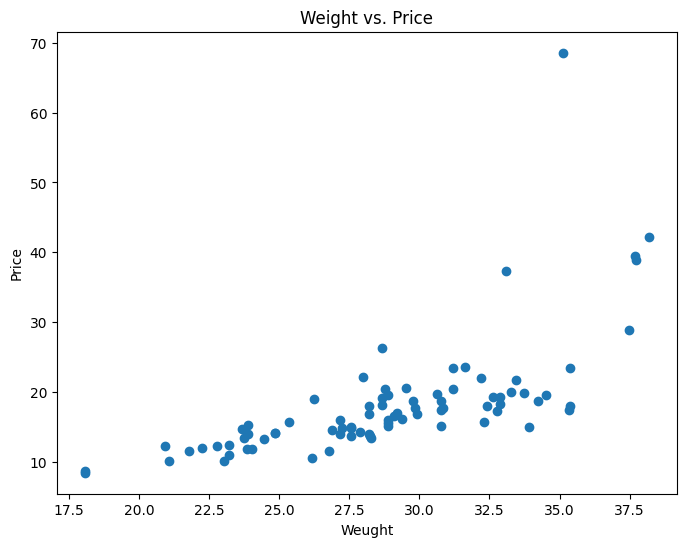

In [30]:
# Data Visualization
plt.figure(figsize=(8, 6))
plt.scatter(df['weight'], df['price'])
plt.xlabel('Weught')
plt.ylabel('Price')
plt.title('Weight vs. Price')
plt.show()

In [31]:
# Fit the overall OLS model
X_all = sm.add_constant(df['weight'])
y_all = df['price']
model_all = sm.OLS(y_all, X_all).fit()
print(model_all.summary())  # Added to see the model summary

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.431
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     60.48
Date:                Tue, 17 Dec 2024   Prob (F-statistic):           2.21e-11
Time:                        08:47:46   Log-Likelihood:                -267.89
No. Observations:                  82   AIC:                             539.8
Df Residuals:                      80   BIC:                             544.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -17.5922      4.651     -3.782      0.0

In [32]:
# Extract residuals
residuals = model_all.resid
# Improved splitting for equal lengths:
n = len(residuals)
split_point = n // 2  # Integer division for the midpoint

In [33]:
resid_group1 = residuals[:split_point]
resid_group2 = residuals[split_point:]

In [34]:
# Ensure equal lengths (truncate if necessary):
min_len = min(len(resid_group1), len(resid_group2))
resid_group1 = resid_group1[:min_len]
resid_group2 = resid_group2[:min_len]

In [35]:
if len(resid_group1) != len(resid_group2):
    print("Error: Could not create equal-length residual groups.") #Should not happen with this method

In [36]:
# Reshape to column vectors:
resid_group1 = resid_group1.values.reshape(-1, 1)
resid_group2 = resid_group2.values.reshape(-1, 1)

In [37]:
results = het_goldfeldquandt(resid_group1, resid_group2)

In [38]:
f_statistic = results[0]
p_value = results[1]

In [39]:
alpha = 0.05
print(f"\nGoldfeld-Quandt F-statistic: {f_statistic}")
print(f"P-value: {p_value}")
if p_value < alpha:
    print("Heteroscedasticity is likely present (reject null hypothesis).")
else:
    print("Heteroscedasticity is not likely present (fail to reject null hypothesis).")


Goldfeld-Quandt F-statistic: 17.044259703079213
P-value: 1.7906999811893394e-08
Heteroscedasticity is likely present (reject null hypothesis).
